# Day 08. Exercise 02
# Multiclass classification. One-hot encoding. Random forest

## 0. Imports

In [411]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## 1. Preprocessing

1. Read the file [`checker-submits.csv`](https://drive.google.com/file/d/14voc4fNJZiLEFaZyd8nEG-lQt5JjatYw/view?usp=sharing).
2. Create a dataframe `df` with the columns: `uid`, `labname`, `numTrials`, `hour`, `dayofweek` where `hour` is extracted from the `timestamp` as well as the `dayofweek` (`0` is Monday, `6` is Sunday). We will try to predict the day of the week having data about which user made a commit for which lab at which hour and which try it was.
3. Using `OneHotEncoder()` transform your categorical features, delete from the dataframe the initial columns.
4. Use `StandardScaler()` and scale your continuous features.
5. Save the dataframe as `dayofweek.csv`.
6. Before trying out different algorithms, find out the accuracy of the naive algorithms – the one that predicts everything as the most popular class.

In [372]:
df = pd.read_csv("../data/checker_submits.csv")
df

,uid,labname,numTrials,timestamp
0,user_4,project1,1,2020-04-17 05:19:02.744528
1,user_4,project1,2,2020-04-17 05:22:45.549397
2,user_4,project1,3,2020-04-17 05:34:24.422370
3,user_4,project1,4,2020-04-17 05:43:27.773992
4,user_4,project1,5,2020-04-17 05:46:32.275104
...,...,...,...,...
1681,user_19,laba06s,9,2020-05-21 20:01:48.959966
1682,user_1,laba06s,6,2020-05-21 20:18:54.487900
1683,user_1,laba06s,7,2020-05-21 20:19:06.872761
1684,user_1,laba06s,8,2020-05-21 20:22:41.877806


In [373]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1686 entries, 0 to 1685
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   uid        1686 non-null   object        
 1   labname    1686 non-null   object        
 2   numTrials  1686 non-null   int64         
 3   timestamp  1686 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 52.8+ KB


In [374]:
df['hour'] = df['timestamp'].dt.hour
df

,uid,labname,numTrials,timestamp,hour
0,user_4,project1,1,2020-04-17 05:19:02.744528,5
1,user_4,project1,2,2020-04-17 05:22:45.549397,5
2,user_4,project1,3,2020-04-17 05:34:24.422370,5
3,user_4,project1,4,2020-04-17 05:43:27.773992,5
4,user_4,project1,5,2020-04-17 05:46:32.275104,5
...,...,...,...,...,...
1681,user_19,laba06s,9,2020-05-21 20:01:48.959966,20
1682,user_1,laba06s,6,2020-05-21 20:18:54.487900,20
1683,user_1,laba06s,7,2020-05-21 20:19:06.872761,20
1684,user_1,laba06s,8,2020-05-21 20:22:41.877806,20


In [375]:
df['dayofweek'] = df['timestamp'].dt.dayofweek
df = df.drop(['timestamp'], axis=1)
df

,uid,labname,numTrials,hour,dayofweek
0,user_4,project1,1,5,4
1,user_4,project1,2,5,4
2,user_4,project1,3,5,4
3,user_4,project1,4,5,4
4,user_4,project1,5,5,4
...,...,...,...,...,...
1681,user_19,laba06s,9,20,3
1682,user_1,laba06s,6,20,3
1683,user_1,laba06s,7,20,3
1684,user_1,laba06s,8,20,3


In [376]:
enc = OneHotEncoder(sparse_output=False).set_output(transform='pandas')

In [377]:
enc_transofrm = enc.fit_transform(df[['uid', 'labname']])
enc_transofrm

,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,uid_user_13,uid_user_14,uid_user_15,uid_user_16,uid_user_17,...,labname_lab02,labname_lab03,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1682,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1683,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1684,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [378]:
scaler = StandardScaler()

In [379]:
X_scaled = pd.DataFrame(scaler.fit_transform(df[['numTrials', 'hour']]), columns=['numTrials', 'hour'], index=df.index)
X_scaled


,numTrials,hour
0,-0.788667,-2.562352
1,-0.756764,-2.562352
2,-0.724861,-2.562352
3,-0.692958,-2.562352
4,-0.661055,-2.562352
...,...,...
1681,-0.533442,0.945382
1682,-0.629151,0.945382
1683,-0.597248,0.945382
1684,-0.565345,0.945382


In [380]:
df = df.drop(['uid', 'labname'], axis=1)

In [381]:
X = pd.concat([enc_transofrm, X_scaled], axis=1)
X

,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,uid_user_13,uid_user_14,uid_user_15,uid_user_16,uid_user_17,...,labname_lab03s,labname_lab05s,labname_laba04,labname_laba04s,labname_laba05,labname_laba06,labname_laba06s,labname_project1,numTrials,hour
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.788667,-2.562352
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.756764,-2.562352
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.724861,-2.562352
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.692958,-2.562352
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.661055,-2.562352
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.533442,0.945382
1682,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.629151,0.945382
1683,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.597248,0.945382
1684,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.565345,0.945382


In [382]:
df_final = pd.concat([X, df['dayofweek']], axis=1)
df_final.shape

(1686, 44)

In [383]:
df_final.to_csv("../data/dayofweek.csv", index=False)

In [384]:
dummy = DummyClassifier(strategy='most_frequent')

In [385]:
X = df_final.drop(columns=['dayofweek'])
y = df_final['dayofweek']

In [386]:
dummy.fit(X, y)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [387]:
dummy_predict = dummy.predict(X)

In [388]:
accuracy_score(y, dummy_predict)

0.23487544483985764

## 2. Algorithms

### a. Logreg

1. Train logistic regression, for the baseline model use `random_state=21`, `fit_intercept=False`. 
2. Calculate the accuracy.
3. Write a function that draws the plot (`barh`) taking coefficients of any trained models, names of the features and the number of `top-n` most important features to display.
4. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model.
5. Remember that it is a multiclass classification and `coef_` returns a matrix, to calculate importance for a feature you need to sum all the individual feature importances for all the target values.

In [389]:
logr = LogisticRegression(random_state=21, fit_intercept=False)

In [390]:
logr.fit(X, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,False
,intercept_scaling,1
,class_weight,None
,random_state,21
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [391]:
logr_predict = logr.predict(X)

In [392]:
accuracy_score(y, logr_predict)

0.6405693950177936

In [393]:
logr.coef_

array([[ 0.88785462, -0.72204057, -1.20961849, -0.13550597,  0.11855261,
        -0.24292383,  0.99315842, -0.57436991,  0.82300001,  0.77921075,
         1.02945227, -0.34735588,  0.59982601,  0.95388361, -1.03573788,
         0.90244523, -0.10581823, -1.03844556, -0.41387058, -1.41540438,
        -0.49179335, -1.30785829,  0.1678781 ,  1.31029322, -0.57032173,
         0.34335525,  0.36371928,  0.12398894, -0.12810522, -0.70780105,
         0.50556905,  0.88785462,  0.55904989,  0.56015816, -0.34319438,
         0.05020533, -0.52339295, -1.74789408, -0.42255079, -0.80388879,
         0.22773136, -0.0297061 ,  0.06074159],
       [-0.09221518, -0.75449458,  0.47822355, -0.07153108,  0.04530364,
         1.87267659,  1.07064883, -0.34860503,  0.11474109, -0.17842324,
        -0.81392866, -0.41684577,  1.49789742, -1.222597  ,  1.37429764,
         0.86819747, -0.55482125,  0.4841519 ,  0.12637135, -1.3717879 ,
        -0.35385988, -0.24326556,  1.0818172 , -0.39094124, -0.37807042,
   

In [394]:
importance = np.sum(np.abs(logr.coef_), axis=0)
importance

array([1.77570923, 6.53171623, 6.12888892, 4.22287172, 5.09568432,
       6.23425914, 9.75518165, 3.68229969, 5.67675292, 6.68533154,
       5.45819233, 5.19275083, 7.88962976, 4.81492288, 6.11715017,
       3.63046318, 3.2367726 , 6.60126164, 4.40897379, 7.08483286,
       6.3351498 , 4.63023575, 5.9413659 , 7.56702257, 2.73642019,
       5.80300084, 6.95317596, 2.70992573, 2.54243098, 5.93420875,
       8.05153572, 1.77570923, 1.11809977, 1.12031633, 5.2726618 ,
       4.09328136, 4.31614867, 7.49637558, 7.80979574, 8.85557751,
       4.79512037, 4.0248825 , 1.28825361])

In [395]:
feature_importance = pd.DataFrame({'features': X.columns, 'importance': importance}).sort_values(by='importance', ascending=False)
feature_importance

,features,importance
6,uid_user_14,9.755182
39,labname_laba06s,8.855578
30,labname_code_rvw,8.051536
12,uid_user_2,7.889630
38,labname_laba06,7.809796
23,uid_user_3,7.567023
37,labname_laba05,7.496376
19,uid_user_26,7.084833
26,uid_user_4,6.953176
9,uid_user_17,6.685332


In [396]:
def top_features(model, n):
    importance = np.sum(np.abs(model.coef_), axis=0)
    feature_importance = pd.DataFrame({'features': X.columns, 'importance': importance}).sort_values(by='importance', ascending=False)
    top_n  = feature_importance.head(n)
    plt.figure(figsize=(15, 8))
    plt.barh(top_n['features'], top_n['importance'])
    plt.gca().invert_yaxis()
    plt.title(f"Top-{n} Feature Importance", fontsize=16, weight="bold")
    

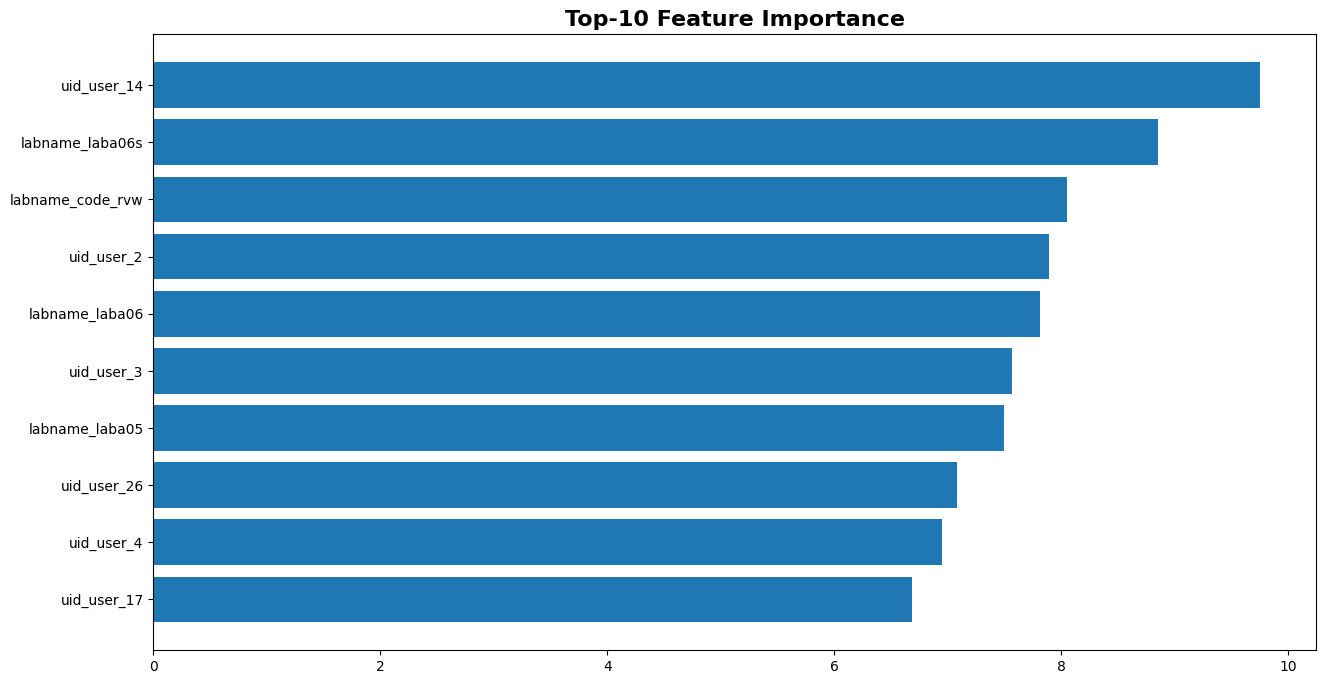

In [397]:
top_features(logr, 10)

### b. SVC

1. Train a `SVC` model, for the baseline model use parameters `kernel='linear'`, `probability=True`, `random_state=21`. 
2. Try different kernels, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model for the linear kernel *

*By default SVC uses “one vs one” strategy of the classification, thus in `coef_` it returns a matrix. To calculate importance for a feature you need to use [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html) over the SVC and sum all the individual feature importances for all the target values.

In [398]:
svc_model_baseline = SVC(kernel='linear', probability=True, random_state=21)
svc_model_poly = SVC(kernel='poly', probability=True, random_state=21)
svc_model_rbf = SVC(kernel='rbf', probability=True, random_state=21)
svc_model_sigmoid = SVC(kernel='sigmoid', probability=True, random_state=21)

In [399]:
svc_model_baseline.fit(X, y)
svc_model_poly.fit(X, y)
svc_model_rbf.fit(X, y)
svc_model_sigmoid.fit(X, y)

,C,1.0
,kernel,'sigmoid'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [400]:
svc_baseline_predicted = svc_model_baseline.predict(X)
svc_poly_predicted = svc_model_poly.predict(X)
svc_rbf_predicted = svc_model_rbf.predict(X)
svc_sigmoid_predicted = svc_model_sigmoid.predict(X)

In [401]:
accuracy_score(y, svc_baseline_predicted), accuracy_score(y, svc_poly_predicted), accuracy_score(y, svc_rbf_predicted), accuracy_score(y, svc_sigmoid_predicted)

(0.702846975088968, 0.8594306049822064, 0.8558718861209964, 0.3997627520759193)

In [402]:
svc_ovr = OneVsRestClassifier(SVC(kernel='linear', probability=True, random_state=21)).fit(X, y)

In [403]:
def top_features_svc(model, n):
    coefs = np.vstack([est.coef_.ravel() for est in model.estimators_])
    importance = np.sum(np.abs(coefs), axis=0)
    feature_importance = pd.DataFrame({'features': X.columns, 'importance': importance}).sort_values(by='importance', ascending=False)
    top_n  = feature_importance.head(n)
    plt.figure(figsize=(15, 8))
    plt.barh(top_n['features'], top_n['importance'])
    plt.gca().invert_yaxis()
    plt.title(f"Top-{n} Feature Importance", fontsize=16, weight="bold")


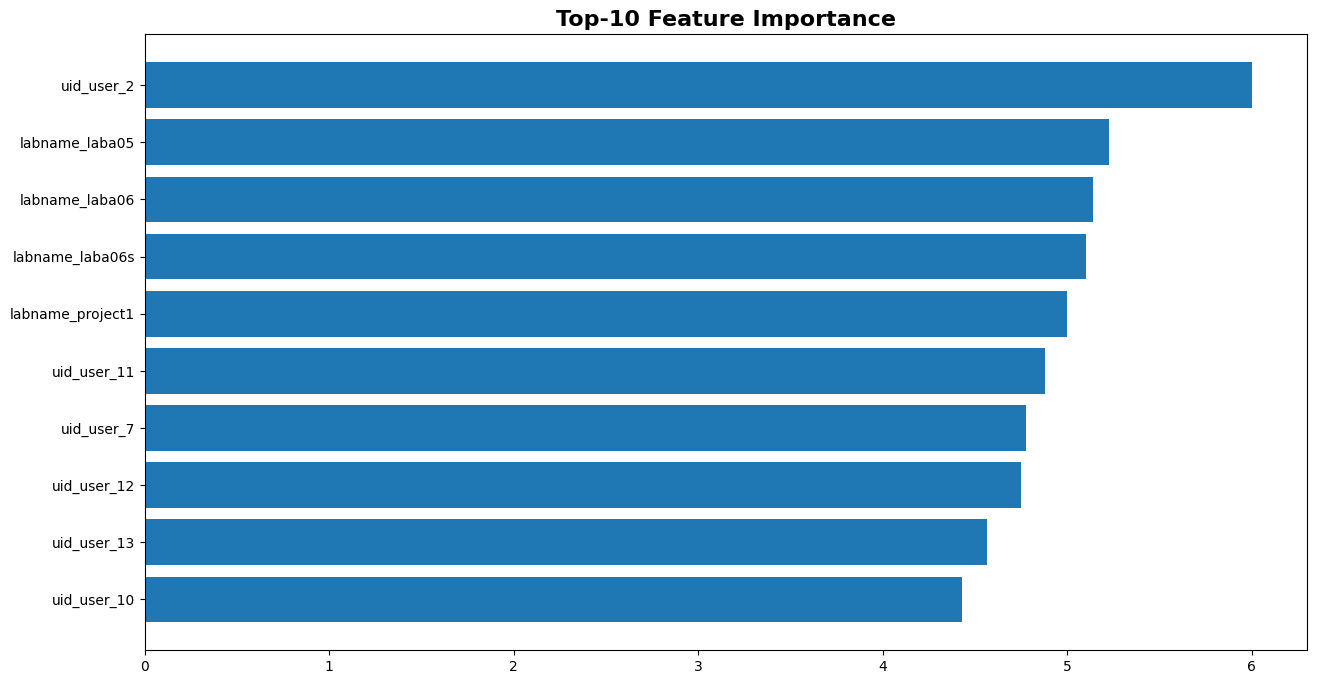

In [404]:
top_features_svc(svc_ovr, 10)

### c. Decision tree

1. Train a `DecisionTreeClassifier` using for the baseline model `max_depth=4`, `random_state=21`. 
2. Try different values of `max_depth`, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model using the written function.

In [405]:
decision_tree_clf = DecisionTreeClassifier(max_depth=4, random_state=21)

In [406]:
decision_tree_clf.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,21
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [407]:
decision_tree_predicted = decision_tree_clf.predict(X)

In [408]:
accuracy_score(y, decision_tree_predicted)

0.5516014234875445

In [409]:
def top_features_dt(model, n):
    importance = model.feature_importances_
    feature_importance = pd.DataFrame({'features': X.columns, 'importance': importance}).sort_values(by='importance', ascending=False)
    top_n  = feature_importance.head(n)
    plt.figure(figsize=(15, 8))
    plt.barh(top_n['features'], top_n['importance'])
    plt.gca().invert_yaxis()
    plt.title(f"Top-{n} Feature Importance", fontsize=16, weight="bold")

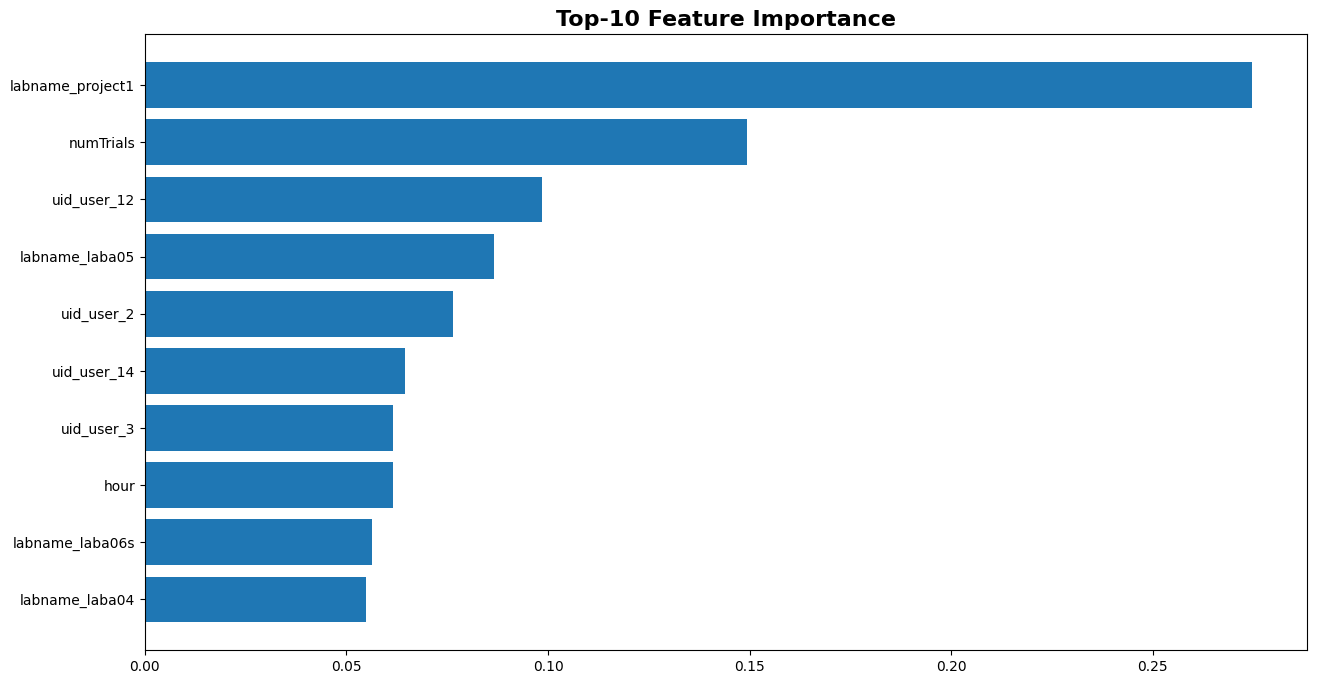

In [410]:
top_features_dt(decision_tree_clf, 10)

### d. Random forest

In real life forest is a set of trees. The same thing is with machine learning. Random forest is a set of individual decision trees (check the documentation for more details).

1. Train a `RandomForestClassifier` using for the baseline model parameters `n_estimators=100`, `max_depth = 25`, `random_state=21`. 
2. Try different values of `max_depth` and `n_estimators`, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model using the written function.

In [444]:
rfc = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)

In [445]:
rfc_model = rfc.fit(X, y)

In [446]:
rfc_model_predicted = rfc_model.predict(X)

In [447]:
accuracy_score(y, rfc_model_predicted)

0.9988137603795967

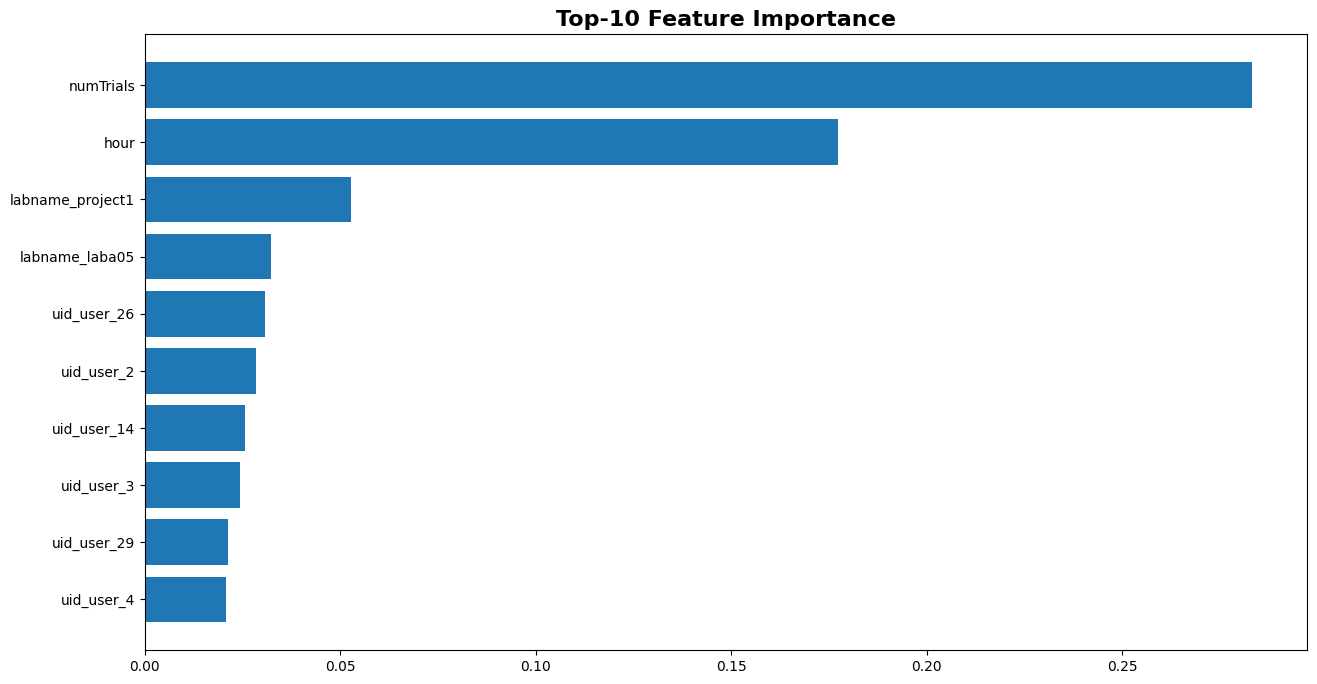

In [448]:
def top_features_rf(model, n):
    importance = model.feature_importances_
    feature_importance = pd.DataFrame({'features': X.columns, 'importance': importance}).sort_values(by='importance', ascending=False)
    top_n  = feature_importance.head(n)
    plt.figure(figsize=(15, 8))
    plt.barh(top_n['features'], top_n['importance'])
    plt.gca().invert_yaxis()
    plt.title(f"Top-{n} Feature Importance", fontsize=16, weight="bold")

top_features_rf(rfc_model, 10)